Name: Adam Dowling
Student ID: C00298483
Date: 13/10/2026
Purpose: Compares the difference in how the jury votes and how the viewing public vote in Eurovision over the years based on their individual semi final scores, where they are placed into clusters for visual representation. 

In [1]:
import pandas as pd

In [2]:
songs = pd.read_csv("archive/Kaggle Dataset/song_data.csv", encoding="latin-1")

In [3]:
import pandas as pd

In [4]:
countries = pd.read_csv('archive/Kaggle Dataset/country_data.csv', encoding='latin-1')

In [5]:
contests = pd.read_csv('archive/Kaggle Dataset/contest_data.csv', encoding='latin-1')

In [6]:
print(songs.shape, countries.shape, contests.shape)

(565, 44) (48, 2) (14, 7)


In [7]:
songs.head()

,year,semi_final,semi_draw_position,final_draw_position,country,artist_name,song_name,language,style,direct_qualifier_10,...,final_jury_votes,final_place,final_total_points,semi_place,semi_televote_points,semi_jury_points,semi_total_points,favourite_10,race,host_10
0,2023,1,1,20,Norway,Alessandra,Queen of Kings,English,Pop,0,...,11.0,5.0,268.0,6.0,102.0,NaN,102.0,0,unknown,0
1,2023,1,2,NaN,Malta,The Busker,Dance (Our Own Party),English,Pop,-,...,NaN,NaN,NaN,15.0,3.0,NaN,3.0,0,unknown,0
2,2023,1,3,5,Serbia,Luke Black,Samo mi se spava,"Serbian, English",Pop,0,...,6.0,24.0,30.0,10.0,37.0,NaN,37.0,0,unknown,0
3,2023,1,4,NaN,Latvia,Sudden Lights,Aija,English,Rock,-,...,NaN,NaN,NaN,11.0,34.0,NaN,34.0,0,unknown,0
4,2023,1,5,2,Portugal,Mimicat,Ai coração,Portuguese,Pop,0,...,9.0,23.0,59.0,9.0,74.0,NaN,74.0,0,unknown,0


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [9]:
from sklearn.cluster import KMeans

Only the televoting and jury semi points columns are kept in the data to be displayed 

In [10]:
X = songs[['semi_televote_points', 'semi_jury_points']].dropna().copy()
songsCleaned = songs.loc[X.index].copy()

In [11]:
print(songsCleaned)

     year semi_final semi_draw_position final_draw_position      country  \
37   2022          1                  1                   -      Albania   
38   2022          1                  2                   -       Latvia   
39   2022          1                  3                  14    Lithuania   
40   2022          1                  4                   5  Switzerland   
41   2022          1                  5                   -     Slovenia   
..    ...        ...                ...                 ...          ...   
273  2016          2                 14                  21      Ukraine   
274  2016          2                 15                   -       Norway   
275  2016          2                 16                  23      Georgia   
276  2016          2                 17                   -      Albania   
277  2016          2                 18                   1      Belgium   

                                artist_name            song_name  \
37                 

In [12]:
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=0)
    kmeans.fit(X)

In [13]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Checka to see exactly how many clusters would be most suitable by using the elbow method

In [14]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=0, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

In [15]:
import seaborn as sns 

In [16]:
sns.set()

The elbow of the graaph is the amount of clusters that the songs can be grouped into

Text(0, 0.5, 'WS')

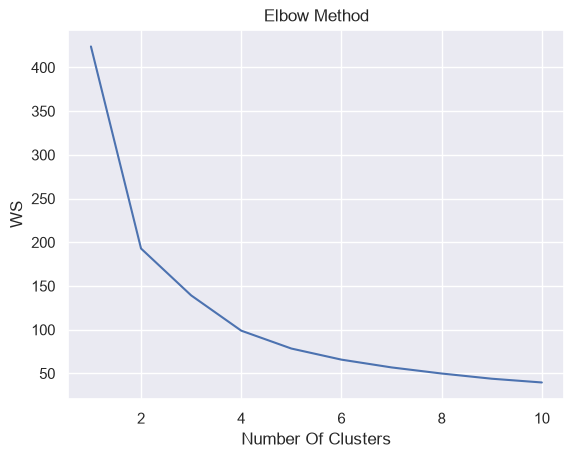

In [17]:
plt.plot(range(1, 11), wcss)
plt.title('Elbow Method')
plt.xlabel('Number Of Clusters')
plt.ylabel('WS')

In [18]:
k = 5

In [19]:
kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)

5 clusters are chosen from the elbow method on the graph

In [20]:
kmeans.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[-0.5

In [21]:
songsCleaned = songs.loc[X.index].copy()
songsCleaned['cluster'] = kmeans.labels_
songsCleaned[['country', 'song_name', 'semi_televote_points', 'semi_jury_points', 'cluster']].head(20)

,country,song_name,semi_televote_points,semi_jury_points,cluster
37,Albania,Sekret,46.0,12.0,3
38,Latvia,Eat Your Salad,16.0,39.0,3
39,Lithuania,Sentimentai,103.0,56.0,1
40,Switzerland,Boys Do Cry,11.0,107.0,0
41,Slovenia,Disko,8.0,7.0,3
42,Ukraine,Stefania,202.0,135.0,2
43,Bulgaria,Intention,18.0,11.0,3
44,Netherlands,De diepte,79.0,142.0,4
45,Moldova,Trenuletul,135.0,19.0,1
46,Portugal,"Saudade, saudade",87.0,121.0,4


In [22]:
songsCleaned['cluster'].value_counts().sort_index()

cluster
0    50
1    41
2    17
3    70
4    34
Name: count, dtype: int64

Plotted based on their televote and jury scores. 

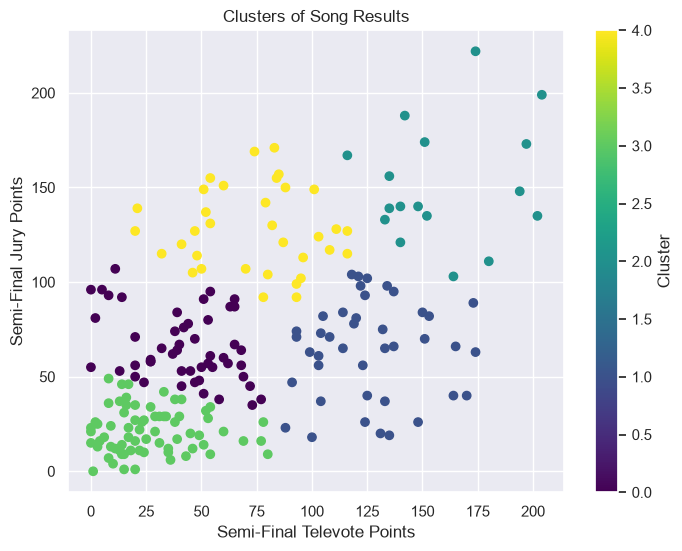

In [23]:
plt.figure(figsize=(8, 6))
plt.scatter(songsCleaned['semi_televote_points'], songsCleaned['semi_jury_points'], c=songsCleaned['cluster'], cmap='viridis')
plt.xlabel('Semi-Final Televote Points')
plt.ylabel('Semi-Final Jury Points')
plt.title('Clusters of Song Results')
plt.colorbar(label='Cluster')
plt.show()

Entries that done good with the jury and less favourably with the telvote

In [24]:
songsCleaned[songsCleaned['cluster'] == 4][['country', 'song_name', 'semi_televote_points', 'semi_jury_points']]

,country,song_name,semi_televote_points,semi_jury_points
44,Netherlands,De diepte,79.0,142.0
46,Portugal,"Saudade, saudade",87.0,121.0
51,Greece,Die Together,60.0,151.0
61,Australia,Not the Same,74.0,169.0
65,Estonia,Hope,96.0,113.0
69,Belgium,Miss You,46.0,105.0
79,Russia,Russian Woman,108.0,117.0
84,Cyprus,El Diablo,78.0,92.0
88,Israel,Set Me Free,93.0,99.0
96,Greece,Last Dance,80.0,104.0


Entries that underperformed with the jury and telvote

In [25]:
songsCleaned[songsCleaned['cluster'] == 3][['country', 'song_name', 'semi_televote_points', 'semi_jury_points']]

,country,song_name,semi_televote_points,semi_jury_points
37,Albania,Sekret,46.0,12.0
38,Latvia,Eat Your Salad,16.0,39.0
41,Slovenia,Disko,8.0,7.0
43,Bulgaria,Intention,18.0,11.0
47,Croatia,Guilty Pleasure,33.0,42.0
...,...,...,...,...
267,North Macedonia,Dona,54.0,34.0
270,Slovenia,Blue and Red,8.0,49.0
272,Denmark,Soldiers of Love,24.0,10.0
274,Norway,Icebreaker,34.0,29.0


Entries that performed really well with both the jury and teevote

In [26]:
songsCleaned[songsCleaned['cluster'] == 2][['country', 'song_name', 'semi_televote_points', 'semi_jury_points']]

,country,song_name,semi_televote_points,semi_jury_points
42,Ukraine,Stefania,202.0,135.0
70,Sweden,Hold Me Closer,174.0,222.0
91,Ukraine,Shum,164.0,103.0
92,Malta,Je me casse,151.0,174.0
100,Iceland,10 Years,148.0,140.0
108,Switzerland,Tout l'univers,135.0,156.0
127,Australia,Zero Gravity,140.0,121.0
148,Netherlands,Arcade,140.0,140.0
163,Israel,Toy,116.0,167.0
176,Norway,That's How You Write a Song,133.0,133.0


Entries with a bad jury score but also an even worse televoting 

In [27]:
songsCleaned[songsCleaned['cluster'] == 1][['country', 'song_name', 'semi_televote_points', 'semi_jury_points']]

,country,song_name,semi_televote_points,semi_jury_points
39,Lithuania,Sentimentai,103.0,56.0
45,Moldova,Trenuletul,135.0,19.0
52,Norway,Give That Wolf a Banana,104.0,73.0
53,Armenia,Snap,105.0,82.0
54,Finland,Jezebel,99.0,63.0
56,Serbia,In corpore sano,174.0,63.0
66,Romania,Llamame,100.0,18.0
67,Poland,River,114.0,84.0
71,Czech Republic,Lights Off,125.0,102.0
77,Lithuania,Discoteque,137.0,66.0


Entries that are middling on an average between their televote and their jury score

In [28]:
songsCleaned[songsCleaned['cluster'] == 0][['country', 'song_name', 'semi_televote_points', 'semi_jury_points']]

,country,song_name,semi_televote_points,semi_jury_points
40,Switzerland,Boys Do Cry,11.0,107.0
50,Iceland,Meo aekkandi sol,39.0,64.0
57,Azerbaijan,Fade to Black,0.0,96.0
64,North Macedonia,Circles,20.0,56.0
80,Sweden,Voices,51.0,91.0
85,Norway,Fallen Angel,77.0,38.0
86,Croatia,Tick-Tock,53.0,57.0
87,Belgium,The Wrong Place,47.0,70.0
89,Romania,Amnesia,27.0,58.0
93,San Marino,Adrenalina,42.0,76.0
